# PDD Similarity Tutorial

This notebook provides a minimal, end-to-end, reproducible example of the PDD predictor's duplicate screening: an **AMD screen** on every structure followed by a **PDD confirmation** of the candidate pairs only.

Before you start:

- Install the requirements from the repository root: `pip install -r requirements.txt` (this notebook needs `average-minimum-distance`, `pymatgen`, `scikit-learn`, `matplotlib` and `pandas`).
- Run the cells from top to bottom. Nothing is random except the t-SNE start, which is seeded (`tsne_random_state = 42`), so you should obtain the same numbers as the ones quoted in the "Expected" notes.

## Demo Example: Find duplicate ZnO structures

Goal: find the duplicate structures among the ZnO CIFs in `tests/fixtures/cif_files` (Materials Project, COD, OQMD and MatterGen), keep one representative per group, and write vectors, a t-SNE embedding, a dendrogram, a heatmap and a provenance file.

The method in one picture:

1. **AMD (Average Minimum Distance)** is cheap: one vector per structure. A pair is a *candidate* if its AMD distance at `k_amd` is at most `tau`.
2. Structures with no candidate partner are unique and are never touched again. The rest form the *reduced subset*.
3. **PDD (Pointwise Distance Distribution)** is more discriminating but costlier. Its Earth Mover's Distance (EMD) at `k_pdd` is computed **only for candidate pairs**.
4. Because AMD distance is a lower bound on PDD EMD (same metric, `k_pdd >= k_amd`), a pair that fails the AMD screen can never pass the PDD test, so nothing is lost.

### Step 1: Set up paths and imports

In this step, you locate the EMOS repository root, put it on `sys.path`, and choose where the results are written.

In [1]:
import json
import shutil
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

# Find the repository root (the folder holding Features/BaseFeature.py and Information_Units/__init__.py).
repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent:
    if (repo_root / "Features" / "BaseFeature.py").is_file() and (repo_root / "Information_Units" / "__init__.py").is_file():
        break
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from Information_Units.Predictors.Pdd.PddPredictor import PddPredictor
from Information_Units.Predictors.Pdd.similarity import ConfigError, Reporter, SimilarityConfig, run_similarity_pipeline
from Information_Units.Predictors.Pdd.similarity.descriptors import amd_distance_matrix, compute_descriptors
from Information_Units.Predictors.Pdd.similarity.loading import (
    CartesianConventionError, check_cartesian, load_structures,
)
from Information_Units.Predictors.Pdd.similarity.optional import species_test
from Information_Units.Predictors.Pdd.similarity.screening import (
    EmdCache, reference_groups, same_partition, screen, stage1_amd,
)

CIF_ROOT = repo_root / "tests" / "fixtures" / "cif_files"
RESULTS_DIR = repo_root / "results" / "pdd_similarity_tutorial"

print(f"Repository root : {repo_root}")
print(f"CIF fixtures    : {CIF_ROOT}")
print(f"Results folder  : {RESULTS_DIR}")

Repository root : <repo>
CIF fixtures    : <repo>\tests\fixtures\cif_files
Results folder  : <repo>\results\pdd_similarity_tutorial


### Step 2: Inspect the CIF fixtures

In this step, you count the CIF files in each source folder. The file-name prefix (`mp-`, `cod-`, `oqmd-`, `mg-`) identifies the source of each structure.

In [2]:
SOURCE_FOLDERS = ["mp", "cod", "oqmd", "mg"]
for folder in SOURCE_FOLDERS:
    print(f"{folder:5s}: {len(list((CIF_ROOT / folder).glob('*.cif')))} CIF files")

mp   : 12 CIF files
cod  : 20 CIF files
oqmd : 39 CIF files
mg   : 51 CIF files


Expected: `mp` 12, `cod` 20, `oqmd` 39, `mg` 51 (122 files). Not every file is ZnO, and one COD file cannot be parsed; the next steps deal with both.

### Step 3: Configure the run

In this step, you describe the run with a `SimilarityConfig`. Every parameter is validated when the object is created.

| Parameter | Meaning |
|---|---|
| `k_amd` | neighbours used for the AMD screen (stage 1) |
| `k_pdd` | neighbours used for the PDD confirmation (stage 2); must be `>= k_amd` |
| `k_max` | neighbours stored per structure; must be `>= k_pdd` |
| `tau` | duplicate threshold in angstrom |
| `metric` | `euclidean`, `cityblock` or `chebyshev`; used for **both** the AMD distances and the EMD ground metric |
| `linkage` | `complete` (every pair in a group is within `tau`), `single`, `average` or `ward` (Euclidean only) |
| `composition_filter` | optional list of reduced formulas to keep |
| `source_prefixes`, `source_priority` | file-name prefix to source label, and the order used to break ties when choosing a representative |

In [3]:
cfg = SimilarityConfig(
    input_dirs=[str(CIF_ROOT / folder) for folder in SOURCE_FOLDERS],
    output_dir=str(RESULTS_DIR),
    composition_filter=["ZnO"],
    source_priority=["COD", "MP", "OQMD", "MATTERGEN"],
    k_amd=15,
    k_pdd=30,
    k_max=100,
    tau=0.1,
    metric="euclidean",
    linkage="complete",
    highlight=["mp-2133", "cod-2300112", "oqmd-4908"],   # drawn on the heatmap only if you list names
    figure_dpi=120,
)
print(json.dumps({k: v for k, v in cfg.to_dict().items() if k in
                  ("k_amd", "k_pdd", "k_max", "tau", "metric", "linkage", "composition_filter")}))

{"composition_filter": ["ZnO"], "k_amd": 15, "k_pdd": 30, "k_max": 100, "tau": 0.1, "metric": "euclidean", "linkage": "complete"}


Invalid configurations are rejected before any structure is read. `cosine` and `correlation` are not norms, so the AMD distance would no longer be a lower bound of the EMD and the screen could drop true duplicates. `k_pdd < k_amd` breaks the same guarantee.

In [4]:
invalid = {
    "k_pdd below k_amd":        dict(k_amd=20, k_pdd=10),
    "cosine metric":            dict(metric="cosine"),
    "correlation metric":       dict(metric="correlation"),
    "ward with cityblock":      dict(linkage="ward", metric="cityblock"),
    "k_max below k_pdd":        dict(k_pdd=30, k_max=20),
}
for label, overrides in invalid.items():
    try:
        replace(cfg, **overrides)
    except ConfigError as exc:
        problems = "; ".join(line.strip(" -") for line in str(exc).splitlines()[1:])
        print(f"rejected  {label:20s} -> {problems}")

rejected  k_pdd below k_amd    -> k_pdd (10) must be >= k_amd (20); otherwise AMD <= EMD no longer holds and the screen could drop true duplicates
rejected  cosine metric        -> metric 'cosine' is not a norm, so AMD <= EMD does not hold and the screen is not lossless; use one of ('euclidean', 'cityblock', 'chebyshev')
rejected  correlation metric   -> metric 'correlation' is not a norm, so AMD <= EMD does not hold and the screen is not lossless; use one of ('euclidean', 'cityblock', 'chebyshev')
rejected  ward with cityblock  -> linkage 'ward' requires metric 'euclidean'
rejected  k_max below k_pdd    -> k_max (20) must be >= k_pdd (30)


### Step 4: Load the structures and check the coordinates

In this step, you read the CIFs with pymatgen (`frac_tolerance=0`, first structure of each file), keep only ZnO, and build one periodic set per structure from **Cartesian** coordinates. Each structure is keyed by `<source>/<relative path>`, so a file name that appears in two folders is never overwritten.

A motif that looks like fractional coordinates passed as Cartesian is a hard error, because it silently produces wrong descriptors.

In [5]:
report = Reporter(verbose=True)
loaded = load_structures(cfg, report)

print(f"\nloaded {len(loaded.records)} | removed by composition filter: {len(loaded.filtered_out)} | "
      f"skipped: {len(loaded.skipped)}")
for item in loaded.skipped:
    print("  skipped:", item)
print("  filtered out:", loaded.filtered_out)

# The guard: a fractional motif passed as Cartesian raises an error.
fractional_motif = np.array([[0.0, 0.0, 0.0], [0.5, 0.5, 0.5]])
try:
    check_cartesian(fractional_motif, 4.2 * np.eye(3), "fractional demo")
except CartesianConventionError as exc:
    print("\nCartesian guard:", exc)

Discovered 122 CIF files: 119 loaded, 1 skipped, 2 removed by the composition filter; parser warnings for 2 files.

loaded 119 | removed by composition filter: 2 | skipped: 1
  skipped: {'name': 'COD/cod-3000626.cif', 'reason': 'parse failed: ValueError: Invalid CIF file with no structures!'}
  filtered out: ['COD/cod-1536063.cif', 'COD/cod-4517837.cif']

Cartesian guard: fractional demo: motif lies wholly in [0,1)^3 - fractional coordinates passed as Cartesian?


Expected: 119 structures loaded, 2 removed by the composition filter (a partially occupied `Zn10.26O48` and `Zn5O12`), and 1 skipped file (`COD/cod-3000626.cif`, no structure inside).

In [6]:
# PDD is computed ONCE per structure at k_max; AMD is derived from it (weighted mean of the rows).
desc, desc_skipped, _ = compute_descriptors(loaded.records, cfg, report)

weight_error = max(abs(p[:, 0].sum() - 1.0) for p in desc.pdd)
nearest = min(p[:, 1].min() for p in desc.pdd)
print(f"structures with descriptors : {len(desc)}")
print(f"largest |sum(weights) - 1|  : {weight_error:.1e}")
print(f"shortest nearest-neighbour  : {nearest:.3f} A")
print(f"AMD matrix shape            : {desc.amd.shape}  (structures x k_max)")

# Optional cross-check against the package's own CIF reader (EMD <= 1e-5 A). Slow, so only 12 files here.
cfg_check = replace(cfg, crosscheck_cifreader=True, k_max=30, k_pdd=30)
_, _, crosscheck_failures = compute_descriptors(loaded.records[:12], cfg_check, Reporter())
print(f"amd.CifReader cross-check failures on 12 files: {len(crosscheck_failures)}")

Descriptors computed for 119 / 119 structures (PDD once, k_max = 100).
structures with descriptors : 119
largest |sum(weights) - 1|  : 2.2e-16
shortest nearest-neighbour  : 1.513 A
AMD matrix shape            : (119, 100)  (structures x k_max)


amd.CifReader cross-check failures on 12 files: 0


### Step 5: Stage 1 - AMD screen on the full set

In this step, you compute all pairwise AMD distances at `k_amd`, mark pairs within `tau` as candidates, and take the connected components of the candidate graph. Structures in singleton components are unique and need no PDD.

In [7]:
d_amd = amd_distance_matrix(desc.amd, cfg.k_amd, cfg.metric)
stage1 = stage1_amd(d_amd, cfg.tau)

n = len(desc)
print(f"structures                    : {n}")
print(f"all pairs                     : {n * (n - 1) // 2}")
print(f"candidate pairs (AMD <= tau)  : {len(stage1.candidate_pairs)}")
print(f"unique after stage 1          : {n - len(stage1.subset)}")
print(f"reduced subset (components >=2): {len(stage1.subset)}")

structures                    : 119
all pairs                     : 7021
candidate pairs (AMD <= tau)  : 663
unique after stage 1          : 25
reduced subset (components >=2): 94


Expected: 663 candidate pairs out of 7021, 25 structures unique after stage 1, and a reduced subset of 94 structures.

### Step 6: Stage 2 - PDD confirmation on candidate pairs only

In this step, you compute the EMD at `k_pdd` for the candidate pairs only. The final distance is the AMD distance where it exceeds `tau` and the PDD EMD otherwise. Groups come from a linkage cut at `tau`; each group's representative is its medoid, with ties broken by source priority and then ID.

The wurtzite and zinc blende polymorphs of ZnO (`mp-2133`, `mp-1986`) have almost the same first 15 neighbour distances, so they pass the AMD screen, but PDD at `k_pdd = 30` tells them apart.

In [8]:
cache = EmdCache(desc.pdd, cfg.metric, cfg.n_jobs)
screened = screen(desc, cfg, cache)

print(json.dumps(screened.counts, indent=2))
print("bound check (AMD <= EMD):", screened.bound_check)

pair = next(row for row in screened.candidate_table
            if {row["a"], row["b"]} == {"MP/mp-2133.cif", "MP/mp-1986.cif"})
print("\nwurtzite vs zinc blende:", pair)
confirmed = sum(row["confirmed"] for row in screened.candidate_table)
print(f"candidates confirmed by PDD: {confirmed} | rejected by PDD: {len(screened.candidate_table) - confirmed}")

{
  "n_structures": 119,
  "n_pairs_total": 7021,
  "n_candidate_pairs": 663,
  "n_components": 39,
  "n_components_multi": 14,
  "n_unique_after_stage1": 25,
  "n_subset": 94,
  "n_pdd_pairs_evaluated": 663,
  "n_pdd_pairs_saved": 6358,
  "n_groups": 71,
  "n_duplicate_groups": 20,
  "n_removed_as_duplicates": 48
}
bound check (AMD <= EMD): {'pairs_checked': 663, 'max_violation_A': 0.0, 'tolerance_A': 0.0010954451150103322, 'holds': True}

wurtzite vs zinc blende: {'a': 'MP/mp-1986.cif', 'b': 'MP/mp-2133.cif', 'amd_A': 0.04386167860122969, 'pdd_emd_A': 1.22868566, 'confirmed': False}
candidates confirmed by PDD: 198 | rejected by PDD: 465


Expected: 71 groups, 6358 of 7021 PDD pairs saved, 198 candidates confirmed and 465 rejected, and `holds: True` in the bound check. The wurtzite / zinc blende pair has AMD distance 0.044 A (a candidate) but PDD EMD 1.229 A (rejected).

### Step 7: Verify the screen against full pairwise PDD grouping

In this step, you check that skipping the PDD calculation for non-candidate pairs changes nothing. With `complete` (or `single`) linkage the groups only depend on which pairs are within `tau`, so the screened groups must be identical to the groups obtained from the EMD of **all** pairs. This evaluates every pair, so it is for verification only. Run it for each allowed metric.

In [9]:
for metric in ("euclidean", "cityblock", "chebyshev"):
    cfg_m = replace(cfg, metric=metric)
    cache_m = EmdCache(desc.pdd, metric)
    screened_m = screen(desc, cfg_m, cache_m)
    identical = same_partition(screened_m.group_labels, reference_groups(desc, cfg_m, cache_m))
    print(f"{metric:10s} identical groups: {identical} | groups: {screened_m.counts['n_groups']:3d} | "
          f"PDD pairs evaluated: {screened_m.counts['n_pdd_pairs_evaluated']:4d} of {screened_m.counts['n_pairs_total']}")
    assert identical and screened_m.bound_check["holds"]

euclidean  identical groups: True | groups:  71 | PDD pairs evaluated:  663 of 7021


cityblock  identical groups: True | groups: 100 | PDD pairs evaluated:  152 of 7021


chebyshev  identical groups: True | groups:  50 | PDD pairs evaluated: 1221 of 7021


### Step 8: Run the full pipeline

In this step, you run everything in one call. The pipeline writes a timestamped `run_<YYYYmmdd_HHMMSS>` folder containing the vectors, the t-SNE embedding, the dendrogram and heatmap, the group tables and `run_info.json`. Figures are only saved, never shown.

In [10]:
result = run_similarity_pipeline(cfg, verbose=True)
RUN_DIR = result.run_dir
print()
for name in sorted(p.name for p in RUN_DIR.iterdir()):
    print(f"  {name}")

Run directory: <repo>\results\pdd_similarity_tutorial\run_20261116_105428


Discovered 122 CIF files: 119 loaded, 1 skipped, 2 removed by the composition filter; parser warnings for 2 files.


Descriptors computed for 119 / 119 structures (PDD once, k_max = 100).


Stage 1 (AMD, k=15, tau=0.1 A): 663 candidate pairs of 7021; 25 structures unique, 94 in the reduced subset.
Stage 2 (PDD EMD, k=30): 663 pairs evaluated, 6358 saved; 71 groups from 119 structures.


t-SNE on PDD EMD at k=30: 94 structures, perplexity 30.0, KL divergence 0.0502


Done. 15 output files written to <repo>\results\pdd_similarity_tutorial\run_20261116_105428

  amd_dendrogram.png
  amd_descriptors.csv
  amd_distance_matrix_k015.csv
  amd_heatmap.png
  candidate_pairs.csv
  cif_metadata.csv
  duplicate_groups.csv
  group_members.csv
  parse_warnings.json
  pdd_emd_matrix_k030.csv
  pdd_store.csv
  pdd_store.pkl
  run_info.json
  tsne.png
  tsne_coords.csv


### Step 9: Inspect the duplicate groups

In this step, you read the group table. Each row is one group of structures that are the same within `tau`; `representative` is the structure to keep.

In [11]:
groups = pd.read_csv(RUN_DIR / "duplicate_groups.csv")
print(f"{len(groups)} groups, {int((groups['n_members'] > 1).sum())} of them with more than one member")
display(groups.sort_values("n_members", ascending=False).head(8)[
    ["group", "representative", "n_members", "sources", "max_intra_A"]])

members = pd.read_csv(RUN_DIR / "group_members.csv")
biggest = groups.sort_values("n_members", ascending=False).iloc[0]["group"]
display(members[members["group"] == biggest][["label", "source", "is_representative", "distance_to_representative_A"]])

71 groups, 20 of them with more than one member


,group,representative,n_members,sources,max_intra_A
2,3,oqmd-1439997,10,COD; OQMD,0.087481
13,14,mg-044,9,MATTERGEN,0.067579
5,6,cod-2300112,7,COD; OQMD,0.071021
3,4,mg-010,5,COD; MATTERGEN,0.068071
51,52,oqmd-339274,4,OQMD,0.040044
4,5,cod-2107059,3,COD; MP,0.072489
27,28,mg-055,3,MATTERGEN,0.067615
8,9,mg-028,3,MATTERGEN,0.037428


,label,source,is_representative,distance_to_representative_A
3,cod-1534836,COD,False,0.066866
4,oqmd-1106917,OQMD,False,0.020615
5,oqmd-1343236,OQMD,False,0.011889
6,oqmd-1439997,OQMD,True,0.000000
7,oqmd-1442030,OQMD,False,0.020298
8,oqmd-1444341,OQMD,False,0.027265
9,oqmd-1472687,OQMD,False,0.015075
10,oqmd-1473257,OQMD,False,0.008318
11,oqmd-328816,OQMD,False,0.023591
12,oqmd-6958,OQMD,False,0.017436


With `complete` linkage, `max_intra_A` is never larger than `tau`: every pair inside a group is within the threshold.

### Step 10: View the figures

In this step, you display the saved figures.

- **Dendrogram** (AMD, whole set): branches are coloured at `tau`, so clusters that merge below the dashed line are duplicates by the AMD screen.
- **Heatmap** (AMD, whole set): lower triangle in the same leaf order as the dendrogram. The highlighted structures come from the `highlight` list in the configuration.
- **t-SNE** (PDD EMD, reduced subset only): structures closer together have more similar PDDs.

Tick labels are hidden automatically when there are more than `max_tick_labels` structures.

amd_dendrogram.png


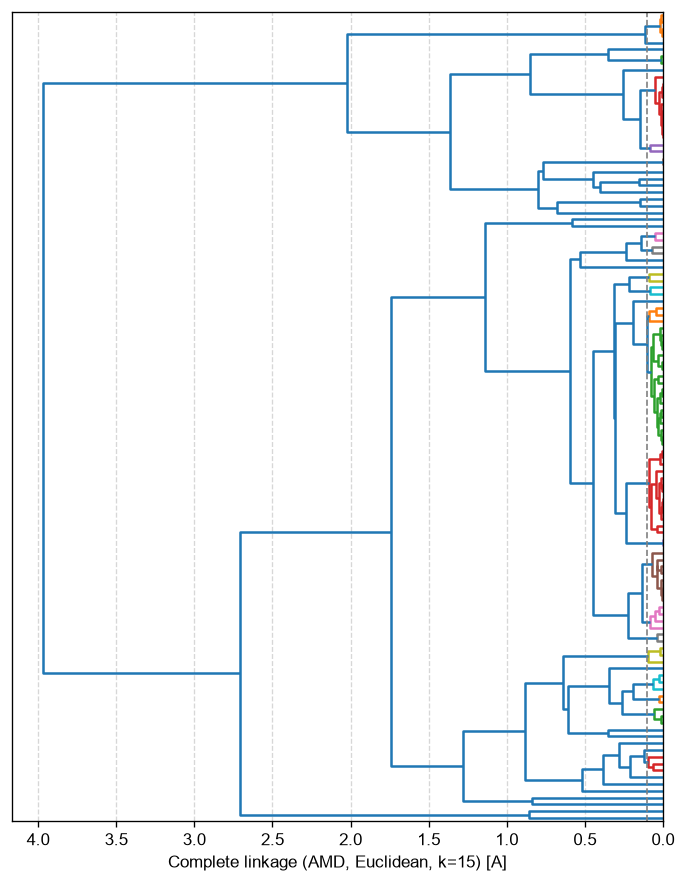

amd_heatmap.png


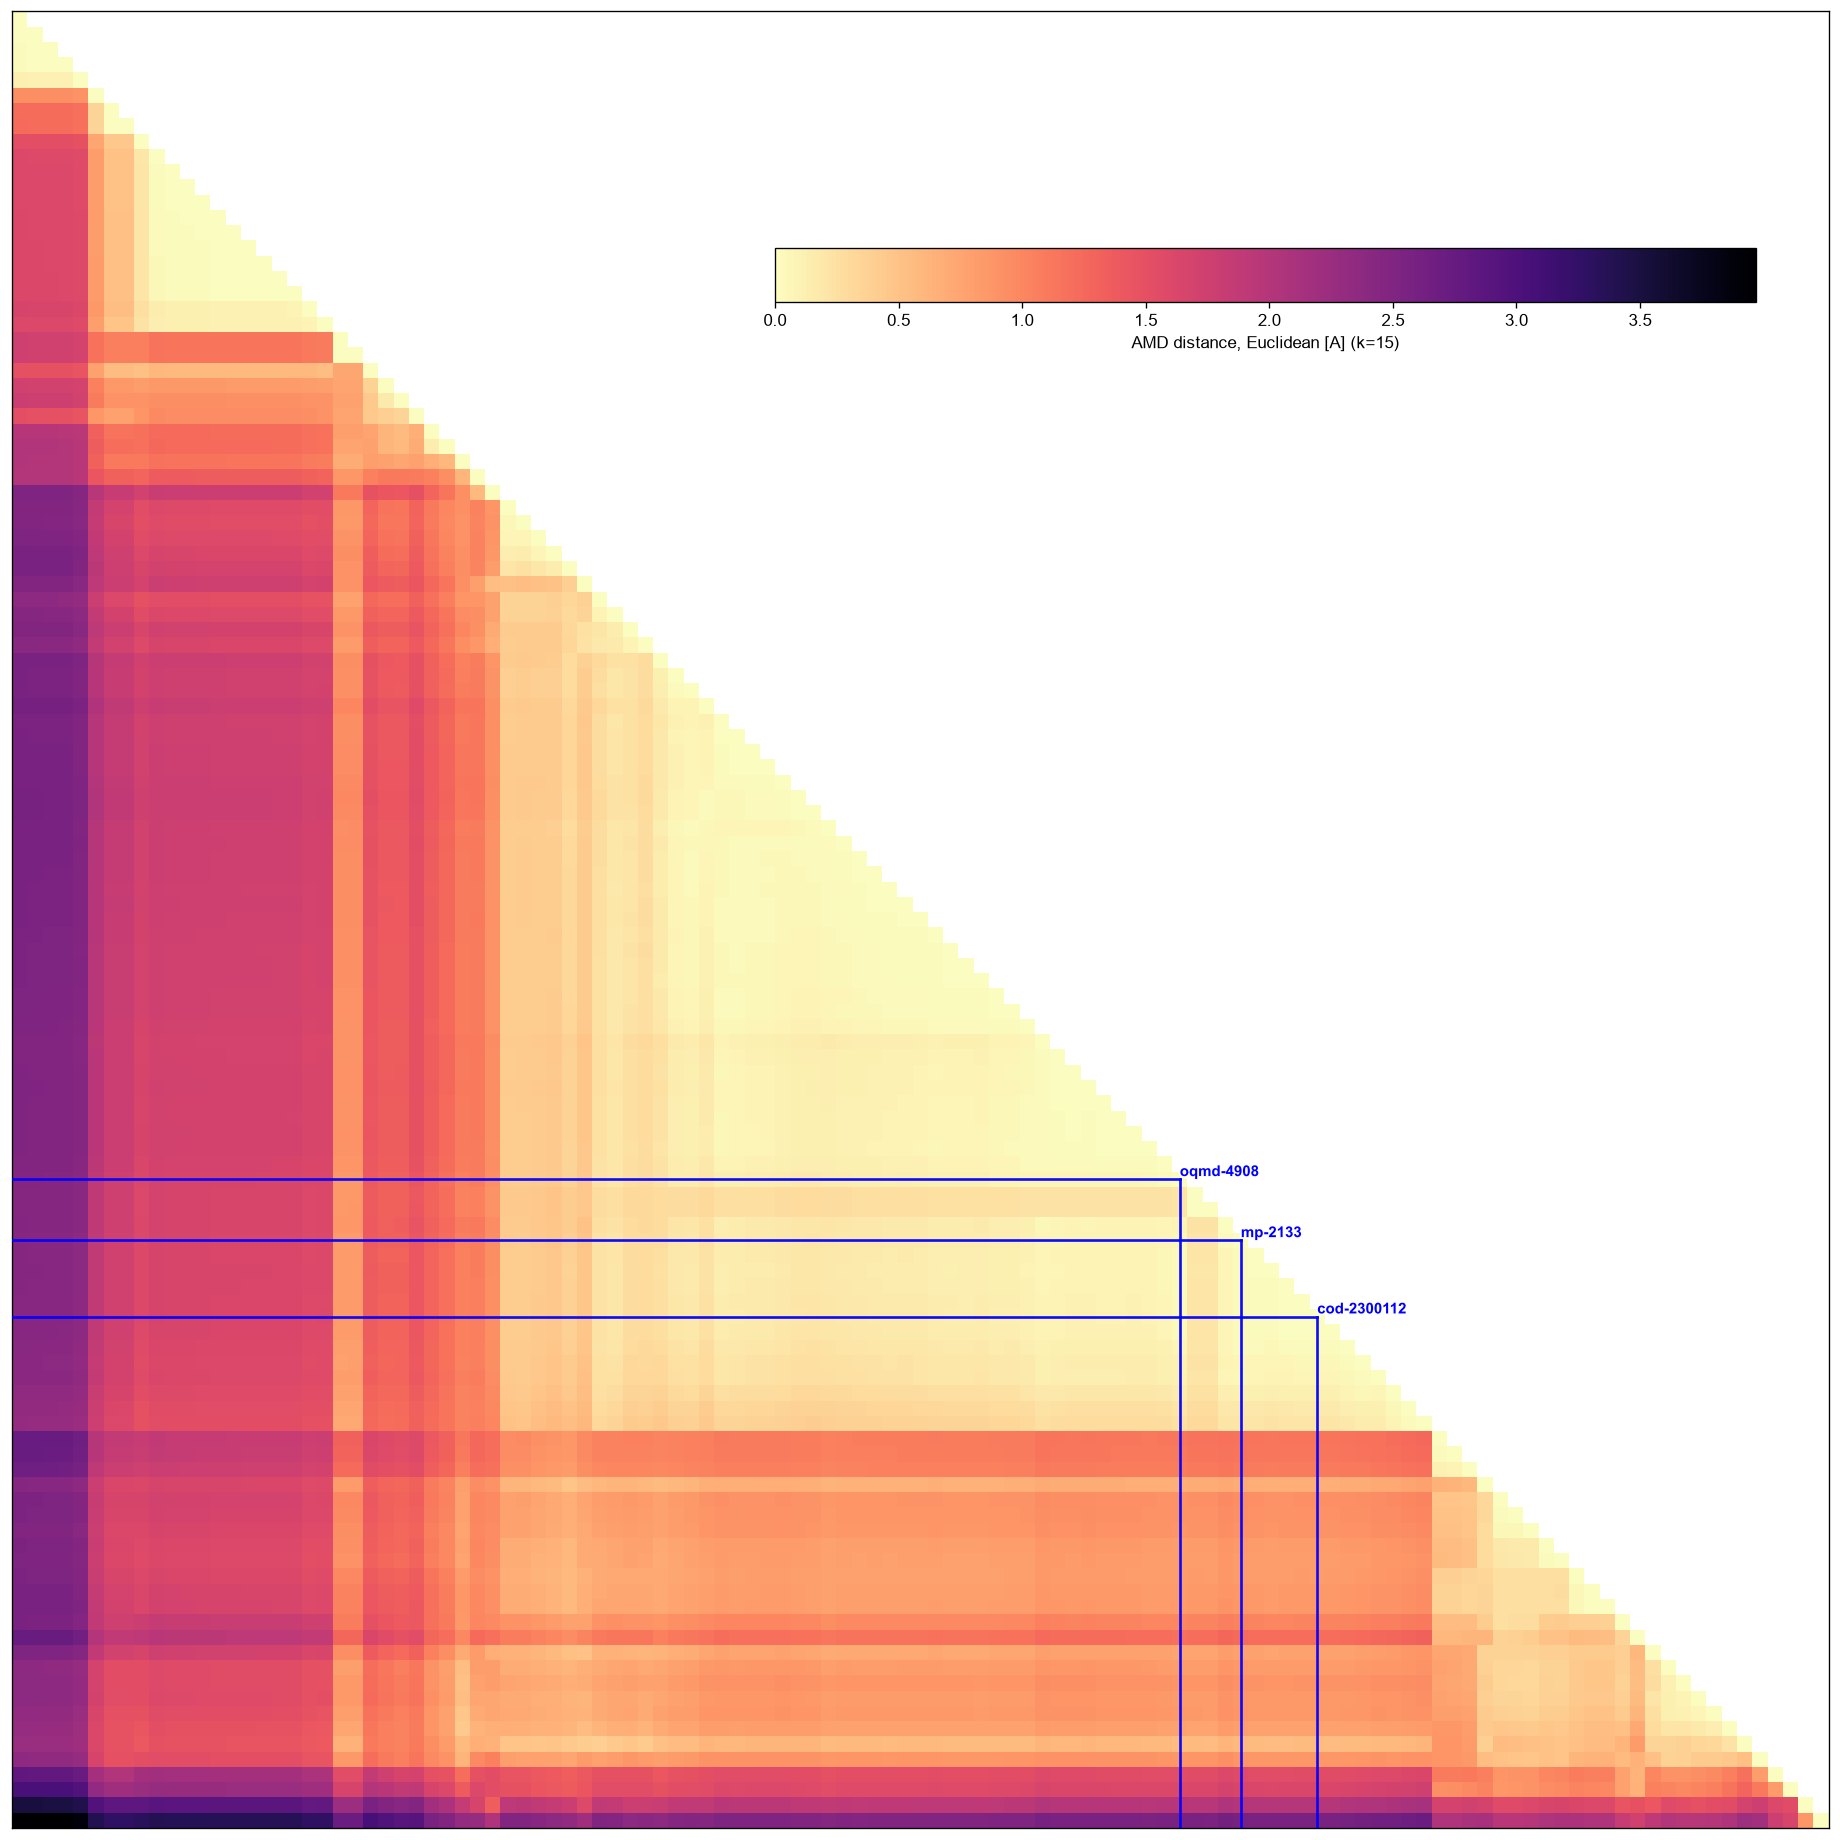

tsne.png


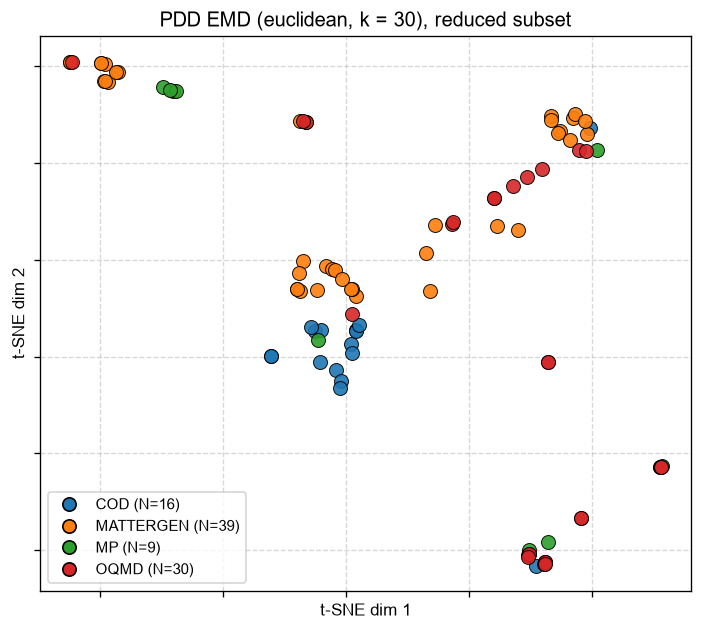

In [12]:
for figure in ("amd_dendrogram.png", "amd_heatmap.png", "tsne.png"):
    print(figure)
    display(Image(filename=str(RUN_DIR / figure), width=600))

### Step 11: Check the descriptors against closed-form values

In this step, you compare the first AMD value (the nearest-neighbour distance) of three cubic ZnO structures with its closed form in terms of the conventional cubic lattice parameter $a$.

In [13]:
closed_forms = {
    "MP/mp-2229.cif":  ("rock salt, a/2",       lambda a: a / 2),
    "MP/mp-1986.cif":  ("zinc blende, sqrt(3)a/4", lambda a: np.sqrt(3) * a / 4),
    "MP/mp-13161.cif": ("CsCl type, sqrt(3)a/2",   lambda a: np.sqrt(3) * a / 2),
}
by_key = {record.key: record for record in loaded.records}
rows = []
for key, (label, formula) in closed_forms.items():
    a_conv = SpacegroupAnalyzer(by_key[key].structure).get_conventional_standard_structure().lattice.a
    amd_1 = float(desc.amd[desc.keys.index(key), 0])
    rows.append({"structure": key, "type": label, "a_conv_A": a_conv, "AMD_1_A": amd_1,
                 "closed_form_A": formula(a_conv), "abs_diff_A": abs(amd_1 - formula(a_conv))})
check = pd.DataFrame(rows)
display(check)
assert check["abs_diff_A"].max() <= 1e-4

,structure,type,a_conv_A,AMD_1_A,closed_form_A,abs_diff_A
0,MP/mp-2229.cif,"rock salt, a/2",4.338884,2.169442,2.169442,4.440892e-16
1,MP/mp-1986.cif,"zinc blende, sqrt(3)a/4",4.558510,1.973892,1.973893,3.223346e-07
2,MP/mp-13161.cif,"CsCl type, sqrt(3)a/2",2.691856,2.331216,2.331216,4.440892e-16


Expected: all three differences are below $10^{-4}$ A.

### Step 12: Species are ignored

In this step, you see the main limitation. AMD and PDD describe **positions only**. If every atom of a structure is relabelled with the same element, nothing in the descriptor changes, so the two structures have distance 0 although their chemistry differs. Use the composition filter (as in this tutorial), or compare within one composition.

In [14]:
print(json.dumps(species_test(by_key["MP/mp-2133.cif"], cfg.k_pdd, cfg.metric, cfg.collapse_tol), indent=2))

{
  "structure": "MP/mp-2133.cif",
  "original_composition": "ZnO",
  "relabelled_composition": "Zn",
  "pdd_emd_A": 0.0,
  "note": "positions identical, species differ: AMD and PDD cannot tell them apart"
}


### Step 13: Read the run provenance

In this step, you read `run_info.json`, which records everything needed to reproduce the run: the parameters, package versions, the input file list, the counts at each stage and every warning.

In [15]:
info = json.loads((RUN_DIR / "run_info.json").read_text(encoding="utf-8"))
print("packages     :", info["packages"])
print("guarantee    :", info["method"]["guarantee"])
print("stage counts :", json.dumps(info["stage_counts"]))
print("bound check  :", info["bound_check"])
print("input files  :", len(info["input_files"]))
print("warnings     :", info["warnings"])

packages     :

 {'average-minimum-distance': '1.6.1', 'pymatgen': '2026.10.24', 'numpy': '2.5.5', 'scipy': '1.16.3', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}
guarantee    : every pair in a group is within tau
stage counts : {"n_structures": 119, "n_pairs_total": 7021, "n_candidate_pairs": 663, "n_components": 39, "n_components_multi": 14, "n_unique_after_stage1": 25, "n_subset": 94, "n_pdd_pairs_evaluated": 663, "n_pdd_pairs_saved": 6358, "n_groups": 71, "n_duplicate_groups": 20, "n_removed_as_duplicates": 48, "n_files_discovered": 122, "n_filtered_out_by_composition": 2, "n_skipped": 1, "n_loaded": 119}
bound check  : {'pairs_checked': 663, 'max_violation_A': 0.0, 'tolerance_A': 0.0010954451150103322, 'holds': True}
input files  : 122
warnings     : ['COD/cod-3000626.cif: could not be parsed (Invalid CIF file with no structures!)']


### Step 14: Run it from the predictor or the command line

In this step, you run the same pipeline through the EMOS predictor, which accepts a plain dictionary. The call below screens only the 12 Materials Project structures.

The command line does the same and accepts a JSON file with any configuration field; command-line options override the file:

```bash
python -m Information_Units.Predictors.Pdd.similarity --input-dir tests/fixtures/cif_files/mp --tau 0.1 --k-amd 15 --k-pdd 30
python -m Information_Units.Predictors.Pdd.similarity --config my_config.json
```

In [16]:
summary = PddPredictor().screen({
    "input_dirs": [str(CIF_ROOT / "mp")],
    "output_dir": str(RESULTS_DIR),
    "k_amd": 15, "k_pdd": 30, "k_max": 50, "tau": 0.1,
    "figure_dpi": 120,
})
print(json.dumps(summary["stage_counts"], indent=2))

{
  "n_structures": 12,
  "n_pairs_total": 66,
  "n_candidate_pairs": 5,
  "n_components": 8,
  "n_components_multi": 3,
  "n_unique_after_stage1": 5,
  "n_subset": 7,
  "n_pdd_pairs_evaluated": 5,
  "n_pdd_pairs_saved": 61,
  "n_groups": 12,
  "n_duplicate_groups": 0,
  "n_removed_as_duplicates": 0
}


### Step 15: Run the tests

Run the PDD tests before submitting a change. They cover configuration validation, the Cartesian guard, the lower bound, screen equivalence for all three metrics, the analytic values above, a regression against an independent AMD computation, and the edge cases (no candidate pairs, fewer than 4 structures, a single structure).

```bash
pytest -q tests/unit/test_pdd_similarity.py tests/integration/test_pdd_similarity_pipeline.py tests/integration/test_pdd_predictor.py
pytest -q tests/standards tests/iu_contracts -k "Pdd or pdd or contract"
```

## Tuning notes

- Lower `tau` finds only closer matches; every group stays within `tau` with `complete` linkage.
- A larger `k_pdd` separates polymorphs that share their nearest neighbours (as the wurtzite / zinc blende pair does) at the price of more EMD work; a larger `k_amd` shrinks the candidate set.
- Keep `k_pdd` well below the number of atoms that fit in your smallest periodic model cell; `cif_metadata.csv` lists `k_reliable` for each structure and the run records a warning when it is exceeded.
- `single` linkage groups chains of near-duplicates; `average` and `ward` have no pairwise guarantee, and the screened result is then an approximation (a warning is recorded).

## Cleanup

Set `CLEAN_UP = True` and run the cell to delete the tutorial results folder.

In [17]:
CLEAN_UP = False
if CLEAN_UP and RESULTS_DIR.exists():
    shutil.rmtree(RESULTS_DIR)
    print(f"removed {RESULTS_DIR}")